# Triplet embedding training
Thuận Minh · Hawkeye · Local RTX 4060 · ResNet-18 · 512-dimensional L2-normalized embeddings

This notebook contains the complete triplet implementation. It reuses the audited RGB cache from notebook 01; every project-specific function is defined here. Run top to bottom in the local CUDA-enabled Python kernel.

The optimized classification backbone is the common warm start for both candidates. They then receive **triplet loss only**. This is practical further training, not an independent comparison of two objectives from ImageNet.

Two identity-balanced mining strategies receive the same pilot budget. Classification-validation retrieval selects the candidate/checkpoint. Kaggle verification pairs and classification test images are not used for training or selection. Final verification ROC/AUC remains a separate task.

Weights, recovery checkpoints and logs remain in git-ignored runs/. Both classification and triplet inference models are exported with explicit preprocessing and provenance.


In [1]:
from pathlib import Path
from dataclasses import dataclass, asdict
from contextlib import contextmanager
import os, json, hashlib, time, math, platform, tempfile, shutil
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
import torchvision
from torchvision.models import resnet18
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ml/face_recognition").is_dir())
DATA_ROOT = ROOT / "data/raw/face_recognition"
CLASSIFICATION_REPORT = ROOT / "runs/face_recognition/classification_optimization_v1/study_report.json"
STUDY_ROOT = ROOT / "runs/face_recognition/triplet_optimization_v1"
STUDY_ROOT.mkdir(parents=True, exist_ok=True)
SEED = 29
PILOT_EPOCHS = 2
MAX_EPOCHS = 20
assert torch.cuda.is_available(), "Use the local CUDA-enabled Python kernel."
torch.set_num_threads(4)
torch.backends.cudnn.benchmark = True
AMP_DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported(including_emulation=False) else torch.float16
print("GPU", torch.cuda.get_device_name(0), "AMP", AMP_DTYPE)
print("Python / torch / torchvision", platform.python_version(), torch.__version__, torchvision.__version__)
print("Study", STUDY_ROOT)

GPU NVIDIA GeForce RTX 4060 Laptop GPU AMP torch.bfloat16
Python / torch / torchvision 3.13.7 2.6.0+cu124 0.21.0+cu124
Study C:\Users\Admin\Downloads\Facial_Recognition_TeamProject\runs\face_recognition\triplet_optimization_v1


In [2]:
def file_sha256(path):
    checksum = hashlib.sha256()
    with path.open("rb") as source:
        for chunk in iter(lambda: source.read(1024 * 1024), b""):
            checksum.update(chunk)
    return checksum.hexdigest()

def write_json(path, value):
    temporary = path.with_name(path.name + f".{os.getpid()}.tmp")
    temporary.write_text(json.dumps(value, indent=2, allow_nan=False) + "\n", encoding="utf-8")
    os.replace(temporary, path)

def save_checkpoint(path, value):
    temporary = path.with_name(path.name + f".{os.getpid()}.tmp")
    with temporary.open("wb") as stream:
        torch.save(value, stream)
        stream.flush()
        os.fsync(stream.fileno())
    os.replace(temporary, path)

@contextmanager
def run_lock(directory):
    with (directory / ".training.lock").open("a+b") as lock:
        lock.write(b"1")
        lock.flush()
        lock.seek(0)
        try:
            if os.name == "nt":
                import msvcrt
                msvcrt.locking(lock.fileno(), msvcrt.LK_NBLCK, 1)
            else:
                import fcntl
                fcntl.flock(lock.fileno(), fcntl.LOCK_EX | fcntl.LOCK_NB)
        except OSError as error:
            raise RuntimeError("Another process is using this training directory") from error
        yield

## Audited data and common initialization

Training has 372,057 eligible images across 4,000 identities. Validation has exactly two images per identity. Manifest, RGB arrays and starting checkpoint must match their recorded SHA-256 digests. The Kaggle verification-pairs file is deliberately not opened.


In [3]:
audit_path = DATA_ROOT / "audit/dataset_report.json"
audit = json.loads(audit_path.read_text(encoding="utf-8"))
assert audit["checks_passed"]
assert file_sha256(Path(audit["manifest"])) == audit["manifest_sha256"]
cache_path = DATA_ROOT / f"classification_cache_{audit['manifest_sha256'][:12]}"
cache_metadata = json.loads((cache_path / "metadata.json").read_text())
assert cache_metadata["manifest_sha256"] == audit["manifest_sha256"]
for filename in ("images.npy", "labels.npy"):
    assert file_sha256(cache_path / filename) == cache_metadata["sha256"][filename]
images_array = np.load(cache_path / "images.npy", mmap_mode="r")
labels_array = np.load(cache_path / "labels.npy", mmap_mode="r")
counts = cache_metadata["counts"]
offsets = {"train": 0, "validation": counts["train"], "test": counts["train"] + counts["validation"]}
class_names = cache_metadata["class_names"]
CLASS_COUNT = len(class_names)
assert images_array.shape == (sum(counts.values()), 64, 64, 3)
assert labels_array.shape == (sum(counts.values()),)
assert images_array.dtype == np.uint8 and labels_array.dtype == np.int64
train_labels = np.asarray(labels_array[:counts["train"]])
identity_labels, identity_starts, identity_counts = np.unique(train_labels, return_index=True, return_counts=True)
assert np.array_equal(identity_labels, np.arange(CLASS_COUNT))
assert (identity_counts >= 4).all()
assert np.array_equal(np.repeat(identity_labels, identity_counts), train_labels)
validation_labels = np.asarray(labels_array[offsets["validation"]:offsets["validation"] + counts["validation"]]).copy()
assert np.array_equal(validation_labels, np.repeat(np.arange(CLASS_COUNT), 2))

classification_report = json.loads(CLASSIFICATION_REPORT.read_text())
source_checkpoint_path = Path(classification_report["selected"]["checkpoint"])
SOURCE_SHA256 = classification_report["selected"]["checkpoint_sha256"]
assert file_sha256(source_checkpoint_path) == SOURCE_SHA256
source_checkpoint = torch.load(source_checkpoint_path, map_location="cpu", weights_only=True)
assert source_checkpoint["class_names"] == class_names
assert source_checkpoint["manifest_sha256"] == cache_metadata["manifest_sha256"]
INPUT_SIZE = source_checkpoint["input_size"][0]
assert INPUT_SIZE == 128 and source_checkpoint["embedding_dimensions"] == 512
INITIAL_STATE = {key: value.clone() for key, value in source_checkpoint["state_dict"].items() if key.startswith("backbone.")}
del source_checkpoint
print(json.dumps({"counts": counts, "classes": CLASS_COUNT, "minimum_images_per_identity": int(identity_counts.min()),
                  "input_size": INPUT_SIZE, "initialization_checkpoint_sha256": SOURCE_SHA256}, indent=2))

{
  "counts": {
    "train": 372057,
    "validation": 8000,
    "test": 7998
  },
  "classes": 4000,
  "minimum_images_per_identity": 13,
  "input_size": 128,
  "initialization_checkpoint_sha256": "f21986bb5881d5a190daabea76a86173c8577bfe3a7ae7b3e99164eea8729896"
}


## Model, inputs and balanced batches

Each batch samples 64 different identities and four distinct images per identity (256 images). Identities are sampled uniformly; images are sampled uniformly within identity. Images can repeat across batches. One sampling epoch has ceil(372,057 / 256) batches and 372,224 image visits, without a unique-image coverage guarantee.

Augmentation uses horizontal flips, mild affine/photometric changes and occasional erasing. MixUp is omitted because its interpolated identities do not fit these triplet labels. The entire backbone is fine-tuned; embeddings are normalized in float32.


In [4]:
@dataclass
class TripletConfig:
    mining: str
    input_size: int = INPUT_SIZE
    identities_per_batch: int = 64
    images_per_identity: int = 4
    epochs: int = MAX_EPOCHS
    seed: int = SEED
    learning_rate: float = 0.00003
    weight_decay: float = 0.0001
    margin: float = 0.2
    erasing_probability: float = 0.05
    minimum_epochs: int = 6
    patience: int = 4

    @property
    def batch_size(self):
        return self.identities_per_batch * self.images_per_identity

CANDIDATES = [TripletConfig("semi_hard"), TripletConfig("batch_hard")]

class FaceEmbedding(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = resnet18(weights=None)
        self.backbone.fc = nn.Identity()

    def forward(self, images):
        return F.normalize(self.backbone(images).float(), dim=1)

def initialize_model(config):
    torch.manual_seed(config.seed)
    torch.cuda.manual_seed_all(config.seed)
    model = FaceEmbedding()
    model.load_state_dict(INITIAL_STATE, strict=True)
    return model.to("cuda", memory_format=torch.channels_last)

def make_optimizer(model, config):
    decay = [p for p in model.parameters() if p.ndim > 1]
    no_decay = [p for p in model.parameters() if p.ndim <= 1]
    return torch.optim.AdamW([
        {"params": decay, "weight_decay": config.weight_decay},
        {"params": no_decay, "weight_decay": 0.0},
    ], lr=config.learning_rate)

MEAN = torch.tensor(cache_metadata["normalization"]["mean"], device="cuda").view(1, 3, 1, 1)
STD = torch.tensor(cache_metadata["normalization"]["std"], device="cuda").view(1, 3, 1, 1)
def raw_batches(split, batch_size, order=None):
    if order is None:
        order = np.arange(counts[split])
    offset = offsets[split]
    for start in range(0, len(order), batch_size):
        indices = np.asarray(order[start:start + batch_size], dtype=np.int64) + offset
        pixels = torch.from_numpy(images_array[indices]).pin_memory()
        labels = torch.from_numpy(np.asarray(labels_array[indices]).copy()).pin_memory()
        yield pixels.to("cuda", non_blocking=True), labels.to("cuda", non_blocking=True)

def make_inputs(raw, size, config=None, generator=None):
    images = raw.permute(0, 3, 1, 2).float().div_(255)
    n = len(images)
    if config is None:
        if size != 64:
            images = F.interpolate(images, size=(size, size), mode="bilinear", align_corners=False, antialias=True)
    else:
        scale = 0.95 + 0.10 * torch.rand(n, device="cuda", generator=generator)
        flip = torch.where(
            torch.rand(n, device="cuda", generator=generator) < 0.5, -1.0, 1.0
        )
        theta = torch.zeros(n, 2, 3, device="cuda")
        theta[:, 0, 0] = scale * flip
        theta[:, 1, 1] = scale
        theta[:, :, 2] = (torch.rand(n, 2, device="cuda", generator=generator) - 0.5) * 0.16
        grid = F.affine_grid(theta, (n, 3, size, size), align_corners=False)
        images = F.grid_sample(images, grid, mode="bilinear", padding_mode="reflection", align_corners=False)
        brightness = 0.9 + 0.2 * torch.rand(n, 1, 1, 1, device="cuda", generator=generator)
        contrast = 0.9 + 0.2 * torch.rand(n, 1, 1, 1, device="cuda", generator=generator)
        centers = images.mean(dim=(2, 3), keepdim=True)
        images = ((images - centers) * contrast + centers).mul_(brightness).clamp_(0, 1)
    images = images.sub(MEAN).div(STD)
    if config is not None and config.erasing_probability > 0:
        active = torch.rand(n, device="cuda", generator=generator) < config.erasing_probability
        height = torch.randint(max(1, size // 10), max(2, size // 4), (n,), device="cuda", generator=generator)
        width = torch.randint(max(1, size // 10), max(2, size // 4), (n,), device="cuda", generator=generator)
        top = torch.randint(0, size, (n,), device="cuda", generator=generator)
        left = torch.randint(0, size, (n,), device="cuda", generator=generator)
        y = torch.arange(size, device="cuda").view(1, size, 1)
        x = torch.arange(size, device="cuda").view(1, 1, size)
        mask = (
            active[:, None, None]
            & (y >= top[:, None, None]) & (y < (top + height)[:, None, None])
            & (x >= left[:, None, None]) & (x < (left + width)[:, None, None])
        )
        images = images.masked_fill(mask[:, None], 0)
    return images.contiguous(memory_format=torch.channels_last)

def balanced_indices(config, epoch):
    rng = np.random.default_rng(config.seed + epoch)
    steps = math.ceil(counts["train"] / config.batch_size)
    for _ in range(steps):
        identities = rng.choice(CLASS_COUNT, config.identities_per_batch, replace=False)
        indices = np.concatenate([
            identity_starts[identity] + rng.choice(identity_counts[identity], config.images_per_identity, replace=False)
            for identity in identities
        ])
        yield indices.astype(np.int64)

def fetch_training_batch(indices):
    raw = torch.from_numpy(images_array[indices]).pin_memory().to("cuda", non_blocking=True)
    labels = torch.from_numpy(np.asarray(labels_array[indices]).copy()).pin_memory().to("cuda", non_blocking=True)
    return raw, labels

## Online triplet mining

Distances are **squared Euclidean distances between unit embeddings**, computed in float32. Both candidates use the farthest same-identity positive, excluding the anchor itself.

- **Semi-hard:** select the nearest different-identity negative farther than the positive. Outside-margin negatives contribute zero. If no farther negative exists, use the nearest negative and record the fallback rate.
- **Batch-hard:** select the nearest different-identity negative.

Loss is mean(max(d_ap - d_an + 0.2, 0)) including zero-loss anchors. This semi-hard variant is explicit and does not claim to reproduce the complete FaceNet training system.


In [5]:
def mined_triplet_loss(embeddings, labels, config):
    with torch.autocast("cuda", enabled=False):
        embeddings = embeddings.float()
        distances = (2 - 2 * embeddings @ embeddings.T).clamp(0, 4)
        same = labels[:, None].eq(labels[None, :])
        positive_mask = same & ~torch.eye(len(labels), device=labels.device, dtype=torch.bool)
        negative_mask = ~same
        valid = positive_mask.any(1) & negative_mask.any(1)
        if not valid.all():
            raise ValueError("Every anchor needs another same-identity image and a negative.")
        positive = distances.masked_fill(~positive_mask, -torch.inf).max(1).values
        nearest_negative = distances.masked_fill(~negative_mask, torch.inf).min(1).values
        fallback = torch.zeros_like(valid)
        if config.mining == "semi_hard":
            farther = negative_mask & (distances > positive[:, None])
            selected = distances.masked_fill(~farther, torch.inf).min(1).values
            fallback = ~farther.any(1)
            negative = torch.where(fallback, nearest_negative, selected)
        elif config.mining == "batch_hard":
            negative = nearest_negative
        else:
            raise ValueError(config.mining)
        losses = F.relu(positive - negative + config.margin)
        return losses.mean(), {
            "active_fraction": losses.gt(0).float().mean().detach(),
            "positive_distance": positive.mean().detach(),
            "negative_distance": negative.mean().detach(),
            "fallback_fraction": fallback.float().mean().detach(),
        }

def check_triplet_miner():
    generator = torch.Generator().manual_seed(SEED)
    vectors = F.normalize(torch.randn(12, 8, generator=generator), dim=1).to("cuda").requires_grad_()
    labels = torch.arange(3, device="cuda").repeat_interleave(4)
    for config in CANDIDATES:
        loss, statistics = mined_triplet_loss(vectors, labels, config)
        matrix = torch.cdist(vectors.detach().cpu(), vectors.detach().cpu()).square().numpy()
        y = labels.cpu().numpy()
        reference = []
        for anchor in range(len(y)):
            positive = max(matrix[anchor, j] for j in range(len(y)) if j != anchor and y[j] == y[anchor])
            negatives = [matrix[anchor, j] for j in range(len(y)) if y[j] != y[anchor]]
            eligible = [d for d in negatives if d > positive]
            negative = min(eligible) if config.mining == "semi_hard" and eligible else min(negatives)
            reference.append(max(positive - negative + config.margin, 0))
        assert abs(loss.item() - np.mean(reference)) < 1e-6
        loss.backward()
        assert torch.isfinite(vectors.grad).all() and vectors.grad.norm() > 0
        vectors.grad = None
    indices = next(balanced_indices(CANDIDATES[0], 0))
    y = train_labels[indices]
    assert len(np.unique(indices)) == 256
    assert np.array_equal(np.unique(y, return_counts=True)[1], np.full(64, 4))
    assert np.array_equal(indices, next(balanced_indices(CANDIDATES[0], 0)))
    print("Reference miner, finite gradients and deterministic balanced sampler checks passed.")

check_triplet_miner()

Reference miner, finite gradients and deterministic balanced sampler checks passed.


## Validation protocol and starting quality

The primary metric is **leave-one-out validation retrieval Recall@1**: retrieve the most similar other validation image among all 7,999 candidates, excluding self. Its identity must match the query. This is an embedding diagnostic, not classifier top-1 accuracy.

Validation identities are the classification identities, so this protocol does not establish recognition accuracy on unseen people. A fixed set of positive/negative pairs made only from classification-validation labels supplies an auxiliary AUC diagnostic. It is not the Kaggle verification-pairs result.


In [6]:
validation_rng = np.random.default_rng(SEED)
validation_groups = np.arange(counts["validation"]).reshape(CLASS_COUNT, 2)
assert np.array_equal(validation_labels[validation_groups[:, 0]], validation_labels[validation_groups[:, 1]])
positive_pairs = validation_groups.copy()
negative_first = np.arange(counts["validation"])
negative_shift = validation_rng.integers(1, CLASS_COUNT, size=len(negative_first))
negative_identities = (validation_labels + negative_shift) % CLASS_COUNT
negative_second = negative_identities * 2 + validation_rng.integers(0, 2, size=len(negative_first))
assert (validation_labels[negative_first] != validation_labels[negative_second]).all()

def rank_auc(positive_scores, negative_scores):
    # Average ranks handle ties exactly for this fixed validation diagnostic.
    values = np.concatenate((positive_scores, negative_scores))
    order = np.argsort(values, kind="stable")
    ordered = values[order]
    starts = np.r_[0, np.flatnonzero(np.diff(ordered)) + 1]
    ends = np.r_[starts[1:], len(ordered)]
    ranks_sorted = np.repeat((starts + 1 + ends) / 2, ends - starts)
    ranks = np.empty(len(values), dtype=np.float64)
    ranks[order] = ranks_sorted
    n_positive, n_negative = len(positive_scores), len(negative_scores)
    return float((ranks[:n_positive].sum() - n_positive * (n_positive + 1) / 2) / (n_positive * n_negative))

def validation_quality(model):
    model.eval()
    started = time.monotonic()
    vectors = []
    with torch.inference_mode():
        for raw, labels in raw_batches("validation", 256):
            z = model(make_inputs(raw, INPUT_SIZE))
            assert z.shape == (len(labels), 512) and torch.isfinite(z).all()
            assert torch.allclose(z.norm(dim=1), torch.ones(len(z), device="cuda"), atol=1e-5)
            vectors.append(z)
        vectors = torch.cat(vectors)
        labels_gpu = torch.from_numpy(validation_labels).to("cuda")
        correct = 0
        for start in range(0, len(vectors), 256):
            similarities = vectors[start:start + 256] @ vectors.T
            local_rows = torch.arange(len(similarities), device="cuda")
            similarities[local_rows, local_rows + start] = -torch.inf
            retrieved = similarities.argmax(1)
            correct += labels_gpu[retrieved].eq(labels_gpu[start:start + len(similarities)]).sum().item()
        positive = (vectors[positive_pairs[:, 0]] * vectors[positive_pairs[:, 1]]).sum(1).cpu().numpy()
        negative = (vectors[negative_first] * vectors[negative_second]).sum(1).cpu().numpy()
        mean_vector_norm = vectors.mean(0).norm().item()
        per_dimension_std = vectors.std(0).mean().item()
    return {
        "images": len(validation_labels), "retrieval_recall_at_1": correct / len(validation_labels),
        "validation_pair_auc": rank_auc(positive, negative),
        "positive_cosine_mean": float(positive.mean()), "negative_cosine_mean": float(negative.mean()),
        "embedding_mean_vector_norm": mean_vector_norm,
        "embedding_dimension_std_mean": per_dimension_std,
        "seconds": time.monotonic() - started,
    }

assert rank_auc(np.array([1., 2.]), np.array([0., 0.5])) == 1
assert rank_auc(np.ones(2), np.ones(2)) == 0.5
baseline_model = initialize_model(CANDIDATES[0])
baseline_quality = validation_quality(baseline_model)
write_json(STUDY_ROOT / "baseline_quality.json", baseline_quality)
print(json.dumps(baseline_quality, indent=2))
del baseline_model
torch.cuda.empty_cache()

{
  "images": 8000,
  "retrieval_recall_at_1": 0.2025,
  "validation_pair_auc": 0.91476571875,
  "positive_cosine_mean": 0.5737656354904175,
  "negative_cosine_mean": 0.39892035722732544,
  "embedding_mean_vector_norm": 0.6314498782157898,
  "embedding_dimension_std_mean": 0.034170232713222504,
  "seconds": 2.941151999984868
}


## Optimization and epoch recovery

AdamW uses a conservative 3e-5 learning rate, cosine decay, clipping and native BF16 on the RTX 4060. Every epoch records active triplets, positive/negative distances, semi-hard fallback rate, sampled visits, throughput and validation metrics. NaN/Inf, malformed batches and embedding normalization failures stop the run.

Epoch-complete recovery saves model, optimizer, scheduler, scaler, history, early-stopping state and CPU/CUDA RNG. Configuration and source/data fingerprints are verified on resume. The classification backbone remains the external benchmark; best.pt selects the best **trained** triplet checkpoint, even if its gain is negative.


In [7]:
def optimization_step(model, optimizer, scaler, inputs, labels, config):
    optimizer.zero_grad(set_to_none=True)
    with torch.autocast("cuda", dtype=AMP_DTYPE):
        embeddings = model(inputs)
    loss, statistics = mined_triplet_loss(embeddings, labels, config)
    assert torch.isfinite(loss), "Non-finite triplet loss"
    scaler.scale(loss).backward()
    scaler.unscale_(optimizer)
    norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
    if not scaler.is_enabled():
        assert torch.isfinite(norm), "Non-finite gradient"
    previous_scale = scaler.get_scale()
    scaler.step(optimizer)
    scaler.update()
    return {"loss": loss.detach().item(), **{k: v.item() for k, v in statistics.items()},
            "skipped_step": int(scaler.get_scale() < previous_scale)}

def train_epoch(model, optimizer, scaler, config, epoch):
    model.train()
    generator = torch.Generator(device="cuda").manual_seed(config.seed + 10000 * epoch)
    totals = {}
    visited = 0
    skipped = 0
    steps = math.ceil(counts["train"] / config.batch_size)
    torch.cuda.synchronize()
    started = time.monotonic()
    for batch, indices in enumerate(balanced_indices(config, epoch), 1):
        raw, labels = fetch_training_batch(indices)
        inputs = make_inputs(raw, INPUT_SIZE, config, generator)
        result = optimization_step(model, optimizer, scaler, inputs, labels, config)
        visited += len(labels)
        skipped += result.pop("skipped_step")
        for key, value in result.items():
            totals[key] = totals.get(key, 0) + value * len(labels)
        if batch % 100 == 0 or batch == steps:
            progress = {
                "status": "training", "mining": config.mining, "epoch": epoch + 1,
                "batch": batch, "batches": steps, "loss": totals["loss"] / visited,
                "images_per_second": visited / (time.monotonic() - started),
            }
            write_json(STUDY_ROOT / "progress.json", progress)
            print(json.dumps(progress), flush=True)
    torch.cuda.synchronize()
    assert visited == steps * config.batch_size
    return {**{key: value / visited for key, value in totals.items()},
            "sampled_image_visits": visited, "skipped_steps": skipped,
            "seconds": time.monotonic() - started}

def score(quality):
    return (quality["retrieval_recall_at_1"], quality["validation_pair_auc"])

def inference_payload(state, config, epoch, quality, purpose="triplet_embedding"):
    return {
        "purpose": purpose, "architecture": "resnet18_embedding",
        "state_dict": state, "embedding_dimensions": 512,
        "input_size": [INPUT_SIZE, INPUT_SIZE], "color_space": "RGB", "pixel_scale": 1 / 255,
        "resize": {"mode": "bilinear", "align_corners": False, "antialias": True},
        "normalization": cache_metadata["normalization"],
        "manifest_sha256": cache_metadata["manifest_sha256"],
        "initialization_checkpoint_sha256": SOURCE_SHA256,
        "training_config": asdict(config) if config else None,
        "epoch": epoch, "validation": quality,
        "threshold": None, "threshold_status": "Pending Kaggle verification calibration",
    }

def train_trial(config, phase_end):
    directory = STUDY_ROOT / config.mining
    directory.mkdir(exist_ok=True)
    with run_lock(directory):
        configuration = {"training": asdict(config), "initialization_checkpoint_sha256": SOURCE_SHA256,
                         "manifest_sha256": cache_metadata["manifest_sha256"]}
        config_path = directory / "config.json"
        if config_path.is_file():
            assert json.loads(config_path.read_text()) == configuration, "Use a new study directory for changed configuration."
        else:
            write_json(config_path, configuration)
        model = initialize_model(config)
        optimizer = make_optimizer(model, config)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, config.epochs, eta_min=1e-6)
        scaler = torch.amp.GradScaler("cuda", enabled=AMP_DTYPE == torch.float16)
        history = []
        best_quality = baseline_quality
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        best_epoch, bad_epochs = 0, 0
        last_path = directory / "last.pt"
        if last_path.is_file():
            last = torch.load(last_path, map_location="cpu", weights_only=True)
            assert last["configuration"] == configuration
            model.load_state_dict(last["state_dict"])
            optimizer.load_state_dict(last["optimizer"])
            scheduler.load_state_dict(last["scheduler"])
            if scaler.is_enabled() and last["scaler"]:
                scaler.load_state_dict(last["scaler"])
            history, best_state, best_quality = last["history"], last["best_state"], last["best_quality"]
            best_epoch, bad_epochs = last["best_epoch"], last["bad_epochs"]
            torch.set_rng_state(last["torch_rng"])
            torch.cuda.set_rng_state_all(last["cuda_rng"])
            del last

        def persist():
            save_checkpoint(directory / "best.pt", inference_payload(best_state, config, best_epoch, best_quality))
            save_checkpoint(last_path, {
                "configuration": configuration, "epoch": len(history),
                "state_dict": model.state_dict(), "optimizer": optimizer.state_dict(),
                "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(),
                "history": history, "best_state": best_state, "best_quality": best_quality,
                "best_epoch": best_epoch, "bad_epochs": bad_epochs,
                "torch_rng": torch.get_rng_state(), "cuda_rng": torch.cuda.get_rng_state_all(),
            })
            write_json(directory / "history.json", history)

        reason = "pilot_complete"
        try:
            if not last_path.is_file():
                persist()
            for epoch in range(len(history), min(phase_end, config.epochs)):
                if epoch >= config.minimum_epochs and bad_epochs >= config.patience:
                    reason = "early_stopping"
                    break
                optimization = train_epoch(model, optimizer, scaler, config, epoch)
                quality = validation_quality(model)
                scheduler.step()
                history.append({"epoch": epoch + 1, "optimization": optimization, "validation": quality})
                if best_epoch == 0 or score(quality) > score(best_quality):
                    best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
                    best_quality, best_epoch, bad_epochs = quality, epoch + 1, 0
                else:
                    bad_epochs += 1
                persist()
                write_json(directory / "status.json", {
                    "status": "running", "completed_epochs": len(history), "best_epoch": best_epoch,
                    "best_validation": best_quality,
                })
                print(json.dumps(history[-1]), flush=True)
            if len(history) >= config.epochs:
                reason = "maximum_epochs"
            checkpoint = directory / "best.pt"
            summary = {
                "mining": config.mining, "configuration": asdict(config),
                "completed_epochs": len(history), "best_epoch": best_epoch,
                "best_validation": best_quality, "directory": str(directory),
                "checkpoint": str(checkpoint), "checkpoint_sha256": file_sha256(checkpoint),
                "stopping_reason": reason,
                "optimization_seconds": sum(row["optimization"]["seconds"] for row in history),
            }
            write_json(directory / "summary.json", summary)
            write_json(directory / "status.json", {"status": reason, **summary})
            return summary
        except BaseException as error:
            write_json(directory / "status.json", {
                "status": "interrupted" if isinstance(error, KeyboardInterrupt) else "failed",
                "completed_epochs": len(history), "error": f"{type(error).__name__}: {error}",
            })
            raise
        finally:
            del model, optimizer, scheduler, scaler, best_state
            torch.cuda.empty_cache()

## Checkpoint next-update regression check

A small real GPU batch verifies that model/optimizer/scaler/RNG restoration reproduces the next update within numerical tolerance, independently of the long run.


In [8]:
import tempfile
check_config = CANDIDATES[0]
check_model = initialize_model(check_config)
check_optimizer = make_optimizer(check_model, check_config)
check_scaler = torch.amp.GradScaler("cuda", enabled=AMP_DTYPE == torch.float16)
check_model.train()
check_indices = next(balanced_indices(check_config, 0)).reshape(64, 4)[:4].reshape(-1)
check_raw, check_labels = fetch_training_batch(check_indices)
check_inputs = make_inputs(check_raw, check_config.input_size)
optimization_step(check_model, check_optimizer, check_scaler, check_inputs, check_labels, check_config)
with tempfile.TemporaryDirectory(prefix="checkpoint_check_", dir=STUDY_ROOT) as temporary:
    temporary = Path(temporary).resolve()
    assert temporary.is_relative_to(STUDY_ROOT.resolve())
    temporary_checkpoint = temporary / "state.pt"
    save_checkpoint(temporary_checkpoint, {
        "state_dict": check_model.state_dict(), "optimizer": check_optimizer.state_dict(),
        "scaler": check_scaler.state_dict(), "torch_rng": torch.get_rng_state(),
        "cuda_rng": torch.cuda.get_rng_state_all(),
    })
    optimization_step(check_model, check_optimizer, check_scaler, check_inputs, check_labels, check_config)
    replay = torch.load(temporary_checkpoint, map_location="cpu", weights_only=True)
    replay_model = initialize_model(check_config)
    replay_model.load_state_dict(replay["state_dict"])
    replay_optimizer = make_optimizer(replay_model, check_config)
    replay_optimizer.load_state_dict(replay["optimizer"])
    replay_scaler = torch.amp.GradScaler("cuda", enabled=AMP_DTYPE == torch.float16)
    if replay_scaler.is_enabled():
        replay_scaler.load_state_dict(replay["scaler"])
    torch.set_rng_state(replay["torch_rng"])
    torch.cuda.set_rng_state_all(replay["cuda_rng"])
    replay_model.train()
    optimization_step(replay_model, replay_optimizer, replay_scaler, check_inputs, check_labels, check_config)
    parameter_difference = max(
        (value - replay_model.state_dict()[name]).abs().max().item()
        for name, value in check_model.state_dict().items() if value.is_floating_point()
    )
    assert parameter_difference < 1e-4, parameter_difference
print("Checkpoint next-update maximum parameter difference", parameter_difference)
del check_model, check_optimizer, check_scaler, replay_model, replay_optimizer, replay_scaler, replay
del check_inputs, check_raw, check_labels
torch.cuda.empty_cache()

Checkpoint next-update maximum parameter difference 0.0


## Export the existing classification embedding model

Export now, before the longer triplet study. The inference payload contains the backbone, RGB/resize/normalization contract, training/data fingerprints and pending-calibration status. The 4,000-class identity head is omitted.


In [9]:
classification_export = source_checkpoint_path.with_name("inference.pt")
classification_payload = inference_payload(
    INITIAL_STATE, None, classification_report["selected"]["best_epoch"], baseline_quality,
    purpose="classification_embedding")
classification_payload["source_checkpoint_sha256"] = SOURCE_SHA256
classification_payload["initialization_checkpoint_sha256"] = classification_report["baseline"]["checkpoint_sha256"]
classification_payload["training_config"] = classification_report["selected"]["configuration"]
classification_payload["classification_validation"] = classification_report["validation"]
save_checkpoint(classification_export, classification_payload)
print("Classification inference export", classification_export)
print("SHA-256", file_sha256(classification_export))
del classification_payload

Classification inference export C:\Users\Admin\Downloads\Facial_Recognition_TeamProject\runs\face_recognition\classification_optimization_v1\resnet18_128\inference.pt
SHA-256 ac551de86cf4c6ffcef3ead85fec36baf017d7f9ab71bc4d1e5c557354336585


## Validation-selected training study

Each strategy receives two pilot epochs from the same warm start. Highest validation retrieval Recall@1 selects the candidate; auxiliary validation-pair AUC breaks ties. The selected candidate continues to at most 20 total epochs, with early stopping after the minimum budget. Frozen pilot snapshots preserve the actual pilot-selection weights.

The selected best.pt must contain at least one trained epoch. Its gain relative to classification is reported even when negative; the study does not silently substitute the untrained warm start as a completed triplet model.


In [10]:
def run_study():
    report_path = STUDY_ROOT / "study_report.json"
    with run_lock(STUDY_ROOT):
        if report_path.is_file():
            result = json.loads(report_path.read_text())
            assert result["manifest_sha256"] == cache_metadata["manifest_sha256"]
            assert result["initialization_checkpoint_sha256"] == SOURCE_SHA256
            assert [row["configuration"] for row in result["pilots"]] == [asdict(c) for c in CANDIDATES]
            for row in [*result["pilots"], result["selected"]]:
                assert file_sha256(Path(row["checkpoint"])) == row["checkpoint_sha256"]
            return result
        environment = {
            "python": platform.python_version(), "torch": str(torch.__version__),
            "torchvision": str(torchvision.__version__), "cuda": torch.version.cuda,
            "gpu": torch.cuda.get_device_name(0), "training_precision": str(AMP_DTYPE),
            "evaluation_precision": "float32",
        }
        write_json(STUDY_ROOT / "environment.json", environment)
        pilots = []
        for config in CANDIDATES:
            pilot_path = STUDY_ROOT / f"pilot_{config.mining}.json"
            if pilot_path.is_file():
                pilot = json.loads(pilot_path.read_text())
                assert pilot["configuration"] == asdict(config)
                assert file_sha256(Path(pilot["checkpoint"])) == pilot["checkpoint_sha256"]
            else:
                pilot = train_trial(config, PILOT_EPOCHS)
                frozen = Path(pilot["directory"]) / "pilot_best.pt"
                shutil.copyfile(pilot["checkpoint"], frozen)
                assert file_sha256(frozen) == pilot["checkpoint_sha256"]
                pilot["checkpoint"] = str(frozen)
                write_json(pilot_path, pilot)
            pilots.append(pilot)
        winner = max(pilots, key=lambda p: (*score(p["best_validation"]), -next(
            i for i,c in enumerate(CANDIDATES) if c.mining == p["mining"])))
        selection = {"mining": winner["mining"], "pilot_epochs": PILOT_EPOCHS,
                     "criterion": "Highest validation retrieval Recall@1, then validation-pair AUC; candidate order breaks exact ties."}
        selection_path = STUDY_ROOT / "selection.json"
        if selection_path.exists():
            assert json.loads(selection_path.read_text()) == selection
        else:
            write_json(selection_path, selection)
        selected_config = next(c for c in CANDIDATES if c.mining == selection["mining"])
        selected = train_trial(selected_config, selected_config.epochs)
        result = {
            "status": "completed", "baseline": baseline_quality, "pilots": pilots,
            "selection": selection, "selected": selected, "environment": environment,
            "manifest_sha256": cache_metadata["manifest_sha256"],
            "initialization_checkpoint_sha256": SOURCE_SHA256,
            "retrieval_gain_percentage_points": 100 * (
                selected["best_validation"]["retrieval_recall_at_1"] - baseline_quality["retrieval_recall_at_1"]),
            "verification_pairs_used": False,
            "scope": "Triplet-only further training from the optimized classification backbone. "
                     "Validation diagnostics use classification-validation identities; Kaggle verification remains pending.",
        }
        write_json(report_path, result)
        write_json(STUDY_ROOT / "progress.json", {"status": "completed", "report": str(report_path)})
        return result

study_result = run_study()
print(json.dumps(study_result, indent=2))

{
  "status": "completed",
  "baseline": {
    "images": 8000,
    "retrieval_recall_at_1": 0.2025,
    "validation_pair_auc": 0.9147613125,
    "positive_cosine_mean": 0.5737650394439697,
    "negative_cosine_mean": 0.3989203870296478,
    "embedding_mean_vector_norm": 0.6314496994018555,
    "embedding_dimension_std_mean": 0.0341702401638031,
    "seconds": 2.8574526999145746
  },
  "pilots": [
    {
      "mining": "semi_hard",
      "configuration": {
        "mining": "semi_hard",
        "input_size": 128,
        "identities_per_batch": 64,
        "images_per_identity": 4,
        "epochs": 20,
        "seed": 29,
        "learning_rate": 3e-05,
        "weight_decay": 0.0001,
        "margin": 0.2,
        "erasing_probability": 0.05,
        "minimum_epochs": 6,
        "patience": 4
      },
      "completed_epochs": 2,
      "best_epoch": 2,
      "best_validation": {
        "images": 8000,
        "retrieval_recall_at_1": 0.234,
        "validation_pair_auc": 0.9817300937

## Results and learning curves

| Model | Selected epoch | Validation Recall@1 | Validation-pair AUC |
| --- | --- | --- | --- |
| Classification warm start | 0 | 20.250% | 0.914766 |
| Pilot semi_hard | 2 | 23.400% | 0.981730 |
| Pilot batch_hard | 2 | 23.200% | 0.975773 |
| Selected triplet | 19 | 26.075% | 0.984445 |

Selected mining: **semi_hard**. Retrieval change versus classification: **+5.825 percentage points**. These diagnostics are not the project verification ROC/AUC result.

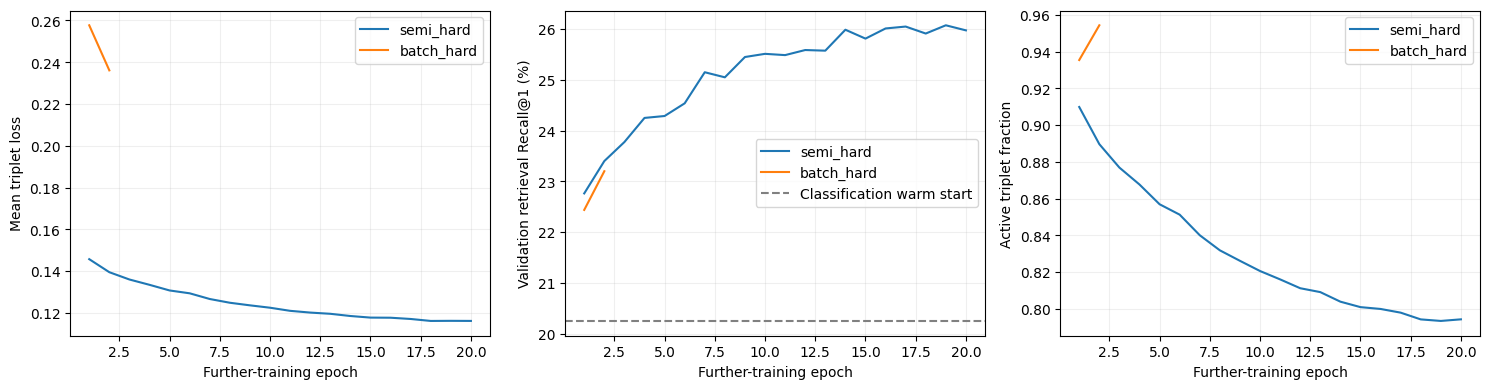

In [11]:
rows = [("Classification warm start", 0, baseline_quality)]
rows += [(f"Pilot {p['mining']}", p["best_epoch"], p["best_validation"]) for p in study_result["pilots"]]
rows += [("Selected triplet", study_result["selected"]["best_epoch"], study_result["selected"]["best_validation"])]
table = ["| Model | Selected epoch | Validation Recall@1 | Validation-pair AUC |",
         "| --- | --- | --- | --- |"]
for name, epoch, quality in rows:
    table.append(f"| {name} | {epoch} | {100*quality['retrieval_recall_at_1']:.3f}% | {quality['validation_pair_auc']:.6f} |")
display(Markdown("\n".join(table)))
display(Markdown(
    f"Selected mining: **{study_result['selection']['mining']}**. "
    f"Retrieval change versus classification: **{study_result['retrieval_gain_percentage_points']:+.3f} percentage points**. "
    "These diagnostics are not the project verification ROC/AUC result."
))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for pilot in study_result["pilots"]:
    history = json.loads((Path(pilot["directory"]) / "history.json").read_text())
    epochs = [row["epoch"] for row in history]
    axes[0].plot(epochs, [row["optimization"]["loss"] for row in history], label=pilot["mining"])
    axes[1].plot(epochs, [100*row["validation"]["retrieval_recall_at_1"] for row in history], label=pilot["mining"])
    axes[2].plot(epochs, [row["optimization"]["active_fraction"] for row in history], label=pilot["mining"])
axes[0].set_ylabel("Mean triplet loss")
axes[1].set_ylabel("Validation retrieval Recall@1 (%)")
axes[2].set_ylabel("Active triplet fraction")
axes[1].axhline(100*baseline_quality["retrieval_recall_at_1"], color="gray", linestyle="--", label="Classification warm start")
for axis in axes:
    axis.set_xlabel("Further-training epoch")
    axis.grid(alpha=0.2)
    axis.legend()
fig.tight_layout()
fig.savefig(STUDY_ROOT / "learning_curves.png", dpi=180, bbox_inches="tight")
plt.show()

### Measured outcome and interpretation

The selected **semi-hard checkpoint from epoch 19** completed a budget of 20 epochs. Batch-hard received two pilot epochs. Training time across both candidates was approximately **63.8 minutes**, excluding checks, validation and file serialization.

Validation retrieval Recall@1 changed from **20.250%** to **26.075%**, a gain of **5.825 percentage points**. Auxiliary classification-validation pair AUC changed from **0.914761** to **0.984445**.

Recall@1 here asks each image to find its single same-person counterpart among 7,999 other validation images. It is not the earlier 4,000-class classifier accuracy. The training curves show diminishing retrieval gains toward the end; the final epoch is not automatically selected. This study measures the two stated candidates and does not establish a global optimum.

Both exported .pt files passed strict restoration, finite 512-dimensional unit-embedding checks and validation reproduction. **The specified Kaggle verification pairs and thresholds remain unevaluated by this notebook.** The inference exports deliberately leave threshold unset.


## Export the triplet model and verify both inference models

Inference exports contain only the embedding backbone, with preprocessing and source/data fingerprints. They return finite 512-dimensional unit vectors. Strict restoration and validation re-evaluation verify the exported triplet state. Thresholds remain unset until Kaggle verification calibration.

best.pt is the validation-selected model; last.pt includes optimizer/RNG recovery and is not the inference export.


In [12]:
selected = study_result["selected"]
assert file_sha256(Path(selected["checkpoint"])) == selected["checkpoint_sha256"]
selected_checkpoint = torch.load(selected["checkpoint"], map_location="cpu", weights_only=True)
assert selected_checkpoint["epoch"] >= 1
selected_checkpoint["source_checkpoint_sha256"] = selected["checkpoint_sha256"]
triplet_export = Path(selected["directory"]) / "inference.pt"
save_checkpoint(triplet_export, selected_checkpoint)
exports = []
for name, path in [("classification", classification_export), ("triplet", triplet_export)]:
    payload = torch.load(path, map_location="cpu", weights_only=True)
    restored = FaceEmbedding().to("cuda", memory_format=torch.channels_last).eval()
    restored.load_state_dict(payload["state_dict"], strict=True)
    raw, _ = next(raw_batches("validation", 8))
    with torch.inference_mode():
        z = restored(make_inputs(raw, INPUT_SIZE))
    assert z.shape == (8, 512) and torch.isfinite(z).all()
    assert torch.allclose(z.norm(dim=1), torch.ones(8, device="cuda"), atol=1e-5)
    restored_quality = validation_quality(restored)
    expected = selected["best_validation"] if name == "triplet" else baseline_quality
    assert abs(restored_quality["retrieval_recall_at_1"] - expected["retrieval_recall_at_1"]) <= 1 / counts["validation"]
    exports.append({"model": name, "path": str(path), "sha256": file_sha256(path), "bytes": path.stat().st_size})
    del restored, payload, z, raw
write_json(STUDY_ROOT / "exports.json", exports)
print(json.dumps(exports, indent=2))
torch.cuda.empty_cache()
display(Markdown("Both inference exports passed strict restoration, validation reproduction and 512-dimensional L2-normalization checks."))

[
  {
    "model": "classification",
    "path": "C:\\Users\\Admin\\Downloads\\Facial_Recognition_TeamProject\\runs\\face_recognition\\classification_optimization_v1\\resnet18_128\\inference.pt",
    "sha256": "ac551de86cf4c6ffcef3ead85fec36baf017d7f9ab71bc4d1e5c557354336585",
    "bytes": 44782722
  },
  {
    "model": "triplet",
    "path": "C:\\Users\\Admin\\Downloads\\Facial_Recognition_TeamProject\\runs\\face_recognition\\triplet_optimization_v1\\semi_hard\\inference.pt",
    "sha256": "1824af326f282df512004d133af868d6184b44f129894e9d179cb52e65e53a1e",
    "bytes": 44782402
  }
]


Both inference exports passed strict restoration, validation reproduction and 512-dimensional L2-normalization checks.

## References and remaining work

- [FaceNet: A Unified Embedding for Face Recognition and Clustering](https://arxiv.org/abs/1503.03832)
- [In Defense of the Triplet Loss for Person Re-Identification](https://arxiv.org/abs/1703.07737)
- [PyTorch AMP examples](https://docs.pytorch.org/docs/2.6/notes/amp_examples.html)

Next: evaluate both models with cosine and Euclidean distance on the specified Kaggle verification pairs, record four ROC/AUC measurements, calibrate thresholds and integrate the chosen model in recognizer.py. The validation diagnostics here do not substitute for that task.
